In [130]:
import os
import numpy as np
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt
import PcmPy as pcm
import EFC_learningfMRI.globals as gl
import EFC_learningfMRI.G_matrix as mat
import EFC_learningfMRI.models as models
import EFC_learningfMRI.vis as vis
import EFC_learningfMRI.util as util

# Representational geometry
## Load data

In [131]:
H        = 'L'
atlas    = 'ROI'
rois     = gl.rois[atlas]
glm      = 3
sns      = gl.participants
sessions = gl.sessions

comp_names = ['identity', 'mean deviation', 'single finger', 'muscle pattern', 'hand use',]

fam_comp = ['identity',
           'single finger', 
           'muscle pattern', 
           'hand use', 
           #'signed force pattern', 
           'mean deviation', 
           #'flexion-extension bias', 
           #'mean force magnitude'
           ]

# colours from Okabe-Ito and Paul Tol's sets, picked so that every pair stays distinguishable under protan-, deutan-
# and tritanopia (simulated, OKLab distance x100 >= 9.7) and under normal vision (>= 22)
palette = {'identity': 'grey',
           'single finger': '#AA4499',     # purple (Tol muted)
           'muscle pattern': '#228833',    # green (Tol bright)
           'hand use': '#56B4E9',          # sky blue (Okabe-Ito)
           'mean deviation': '#E69F00',    # orange (Okabe-Ito)
           }

print(f'N={len(sns)}')

N=16


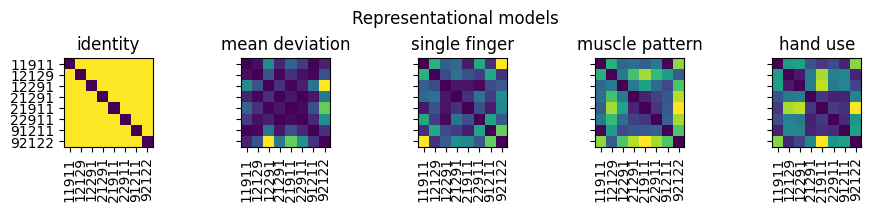

In [132]:
sn = 104
M  = models.make_models(sn, glm=glm, Hem=H, roi=rois[0], comp_names=comp_names)
Mc = M[-2]

# one panel per component; no sharex/sharey: shared axes share the tick formatter
fig, axs = plt.subplots(1, len(comp_names), figsize=(9, 2), constrained_layout=True, sharex=True, sharey=True)

for i, (G, name) in enumerate(zip(Mc.Gc, comp_names)):
    ax = axs[i]
    d  = pcm.G_to_dist(mat.G_sorted(G, sn, order=gl.chordID))   # off the participant's trained-first order, onto gl.chordID
    ax.imshow(d)
    ax.set_xticks(np.arange(8))
    ax.set_xticklabels(gl.chordID, rotation=90)
    ax.set_yticks(np.arange(8))
    ax.set_yticklabels(gl.chordID)
    ax.set_title(name)

fig.suptitle('Representational models')

fig.savefig(os.path.join(gl.figDir, 'representational_models.pdf'))

plt.show()

## Crossnobis distances in each session

In [133]:
# crossnobis distances, participants x sessions x ROIs x chords x chords
D = np.zeros((len(sns), len(sessions), len(rois), len(gl.chordID), len(gl.chordID)))

for s, sn in enumerate(sns):
    for e, session in enumerate(sessions):
        for r, roi in enumerate(rois):
            fname = f'G_obs_raw.within_session.{session}.glm{glm}.{H}.{roi}.npy'
            G     = np.load(os.path.join(gl.baseDir, gl.geomDir, f'subj{sn}', fname))
            G     = mat.G_sorted(G, sn, order=gl.chordID)     # stored trained-first, put on a common chord order
            D[s, e, r] = pcm.G_to_dist(G)

D_mean = D.mean(axis=0)     # group mean, sessions x ROIs x chords x chords

In [ ]:
# one figure: sessions in rows, ROIs in columns; same colour scale across sessions and ROIs; tick marks on both axes
# of every RDM; chord labels: x labels on the last session of every ROI, y labels on the first session of the first
# ROI only; ROI names on top, session names on the right of the last column
vmin, vmax = 0, .3
frame_lw   = .4                                         # line width of the frame around each RDM, and of its tick marks

# per-finger symbol, as gl.chord_digit_letter: 1 extension (filled up triangle), 2 flexion (filled down triangle),
# 9 no press (empty square; in DejaVu Sans its side equals the triangles' base);
# the x labels are the same strings as the y labels, rotated by 90 degrees
digit_symbol = {'1': '▲', '2': '▼', '9': '□'}
chord_labels = [''.join(digit_symbol[d] for d in str(c)) for c in gl.chordID]

n_sess   = len(sessions)
fig, axs = plt.subplots(n_sess, len(rois), figsize=(8, 3.4), layout='constrained')

# no padding between panels: the panels are limited by the figure height, so every bit of vertical space goes to the RDMs
fig.get_layout_engine().set(w_pad=0, h_pad=0, hspace=0, wspace=0)

for r, roi in enumerate(rois):
    for e, session in enumerate(sessions):
        ax = axs[e, r]
        im = ax.imshow(D_mean[e, r], vmin=vmin, vmax=vmax, cmap='viridis')
        ax.set_xticks(np.arange(len(gl.chordID)))
        ax.set_yticks(np.arange(len(gl.chordID)))
        ax.tick_params(width=frame_lw, labelbottom=False, labelleft=False)
        if e == n_sess - 1:
            ax.tick_params(labelbottom=True)
            ax.set_xticklabels(chord_labels, rotation=90, fontsize=4)
        if r == 0 and e == 0:
            ax.tick_params(labelleft=True)
            ax.set_yticklabels(chord_labels, fontsize=4)
        if r == len(rois) - 1:
            ax.yaxis.set_label_position('right')
            ax.set_ylabel(f'session {session}', fontsize=7, rotation=270, labelpad=8)
        for spine in ax.spines.values():
            spine.set_linewidth(frame_lw)

    axs[0, r].set_title(roi)

fig.colorbar(im, ax=axs, fraction=.02, shrink=.6, label='crossnobis distance')

fig.suptitle(f'Crossnobis distances, {H} hemisphere')

fig.savefig(os.path.join(gl.figDir, f'crossnobis_sessions.glm{glm}.{atlas}.{H}.pdf'))

plt.show()

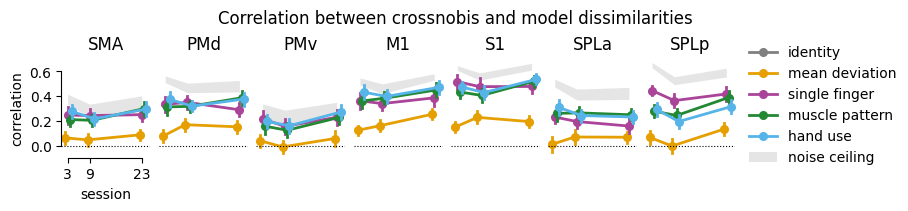

In [135]:
model_corr = pd.read_csv(os.path.join(gl.baseDir, gl.geomDir, f'model_correlation.within_session.{atlas}.glm{glm}.tsv'), sep='\t')

corr = model_corr[(model_corr.Hem == H) & (model_corr.model.isin(comp_names))].copy()

# noise ceiling: lower and upper are one value per participant, session and ROI (repeated on every model row),
# so take one model's rows and average across participants
ceil_rows = model_corr[(model_corr.Hem == H) & (model_corr.model == comp_names[0])]
ceil      = ceil_rows.groupby(['roi', 'session'])[['lower', 'upper']].mean()

fig, axs = plt.subplots(1, len(rois), sharey=True, sharex=True, figsize=(9, 2), constrained_layout=True)

vis.plot_im_sess(fig, axs, model_corr[model_corr.Hem == H], rois, y='r', x='session', hue='model',
                 hue_order=comp_names, palette=palette, kind='point', dodge=.4, add_zero=True)

# grey polygon from the lower to the upper noise ceiling, through the three sessions (x is the session number, as in plot_im_sess)
for r, roi in enumerate(rois):
    ceil_roi = ceil.loc[roi]
    label    = 'noise ceiling' if r == len(rois) - 1 else None     # one legend entry, on the panel that holds the legend
    axs[r].fill_between(ceil_roi.index, ceil_roi.lower, ceil_roi.upper, color='grey', alpha=.2, lw=0, zorder=0, label=label)

sb.despine(ax=axs[0], trim=True)
axs[0].set_ylabel('correlation')
axs[0].set_xlabel('session')
axs[-1].legend([], frameon=False, loc='upper right')
fig.legend(frameon=False, loc='outside right center')

fig.suptitle('Correlation between crossnobis and model dissimilarities')

fig.savefig(os.path.join(gl.figDir, f'correlations_with_models.glm{glm}.{atlas}.{H}.pdf'))

plt.show()

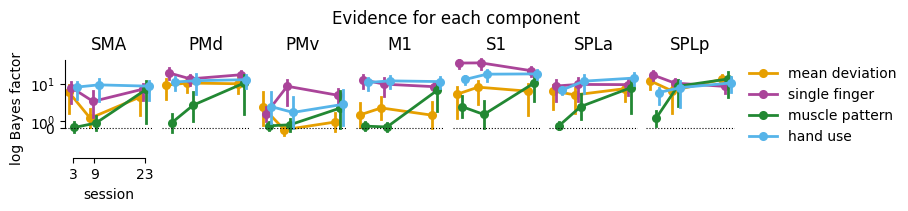

In [136]:
# log Bayes factor of each component, from the sub-family of the PCM model family built only from comp_names
# (all their combinations), with identity required, so each Bayes factor is the gain over the models without that
# component, all of which already hold identity (same family as component_model.ipynb)
# (written by: python scripts/component_model.py, model_family.likelihood.*.tsv)
mf_likelihood = pd.read_csv(os.path.join(gl.baseDir, gl.pcmDir, f'model_family.likelihood.{atlas}.glm{glm}.tsv'), sep='\t')
penalty       = 1                                       # AIC: 1 per component

bf_require = ['identity']
bf_comp    = [c for c in comp_names if c not in bf_require]   # the require'd components get no Bayes factor
bf         = util.component_bayesfactor(mf_likelihood, 
                                        family=comp_names, 
                                        require=bf_require, 
                                        penalty=penalty)
bf         = bf[bf.Hem == H]

fig, axs = plt.subplots(1, len(rois), sharey=True, sharex=True, figsize=(9, 2), constrained_layout=True)

vis.plot_im_sess(fig, axs, bf, rois, y='log_bf', x='session', hue='component',
                 hue_order=bf_comp, palette=palette, kind='point', add_zero=True, dodge=.4, )

sb.despine(ax=axs[0], trim=True)
axs[0].set_ylabel('log Bayes factor')
axs[0].set_yscale('symlog', linthresh=5)
axs[0].set_xlabel('session')
axs[-1].legend([], frameon=False, loc='upper right')
fig.legend(frameon=False, loc='outside right center')

fig.suptitle('Evidence for each component')

fig.savefig(os.path.join(gl.figDir, f'bayes_factor_components.glm{glm}.{atlas}.{H}.pdf'))

plt.show()

In [137]:
# one-sided t-test of the log Bayes factor against 0 across participants, per component, ROI and session
# (uncorrected p-values)
stats = []
for c in bf_comp:
    stat = util.ttest_im_sess(bf[bf.component == c], rois, y='log_bf', x='session', alternative='greater')
    stat['component'] = c
    stats.append(stat)
stats = pd.concat(stats, ignore_index=True)

stats['component'] = pd.Categorical(stats.component, categories=bf_comp, ordered=True)   # components in bf_comp order
stats['roi']       = pd.Categorical(stats.roi, categories=rois, ordered=True)            # ROIs in gl.rois[atlas] order
stats = stats.sort_values(by=['component', 'roi', 'session'])

print(stats.round(3).to_string(index=False))

 roi  session      A  B      T  dof  p_val         CI95  cohen_d  BF10  power      component
 SMA        3 log_bf  0  1.650   15  0.060 [-0.35, inf]    0.413   NaN  0.472 mean deviation
 SMA        9 log_bf  0  1.140   15  0.136 [-0.78, inf]    0.285   NaN  0.289 mean deviation
 SMA       23 log_bf  0  1.759   15  0.050  [0.01, inf]    0.440   NaN  0.514 mean deviation
 PMd        3 log_bf  0  1.856   15  0.042  [0.51, inf]    0.464   NaN  0.550 mean deviation
 PMd        9 log_bf  0  2.031   15  0.030  [1.47, inf]    0.508   NaN  0.615 mean deviation
 PMd       23 log_bf  0  2.092   15  0.027  [1.65, inf]    0.523   NaN  0.637 mean deviation
 PMv        3 log_bf  0  1.154   15  0.133 [-1.58, inf]    0.288   NaN  0.294 mean deviation
 PMv        9 log_bf  0 -0.288   15  0.611 [-1.54, inf]    0.072   NaN  0.027 mean deviation
 PMv       23 log_bf  0  0.695   15  0.249 [-1.35, inf]    0.174   NaN  0.163 mean deviation
  M1        3 log_bf  0  1.123   15  0.139 [-1.07, inf]    0.281   NaN